
Un equipo de TI desea clasificar conexiones como normales (0) o sospechosas (1), a partir del tráfico y la latencia. Compararemos cuatro kernels de SVM y un árbol de decisión.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
COLORES = ['#0891b2', '#f97316']
SEMILLA = 240


In [4]:
datos=pd.read_csv("conexiones_red.csv")

In [5]:
datos.head()

,id_conexion,trafico_mbps,latencia_ms,clase
0,1,52.84,80.41,1
1,2,70.12,54.52,1
2,3,72.36,82.56,0
3,4,62.59,70.85,1
4,5,56.78,91.92,0


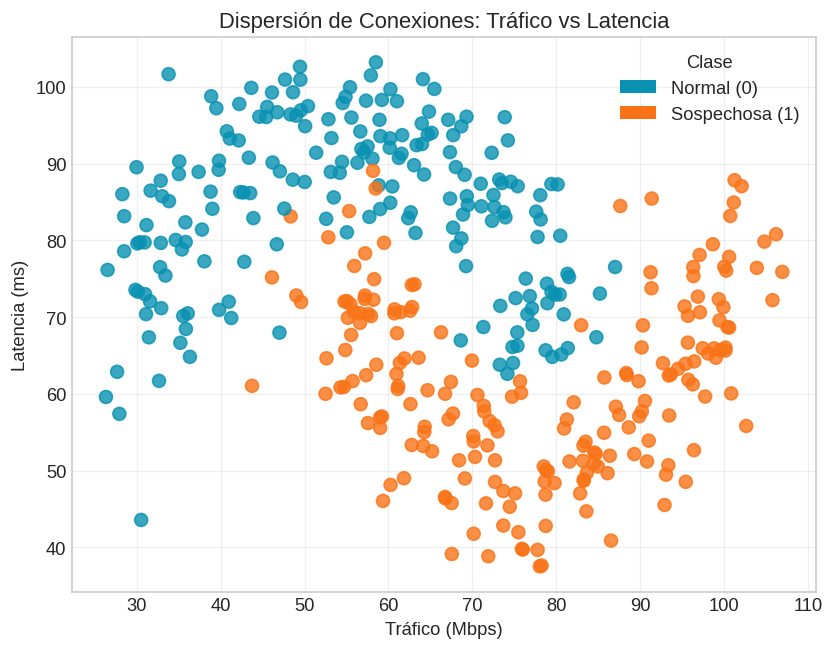

In [7]:
import matplotlib.pyplot as plt

# Definimos las variables x e y usando los datos de nuestro DataFrame
x = datos['trafico_mbps']
y = datos['latencia_ms']
colores_puntos = datos['clase'].map({0: COLORES[0], 1: COLORES[1]})

plt.figure(figsize=(8, 6))
scatter = plt.scatter(x, y, c=colores_puntos, s=60, alpha=0.8)

plt.title("Dispersión de Conexiones: Tráfico vs Latencia")
plt.xlabel("Tráfico (Mbps)")
plt.ylabel("Latencia (ms)")
plt.grid(True, alpha=0.3)

# Añadimos una leyenda manual para identificar las clases
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=COLORES[0], label='Normal (0)'),
    Patch(facecolor=COLORES[1], label='Sospechosa (1)')
]
plt.legend(handles=legend_elements, title="Clase")

plt.show()

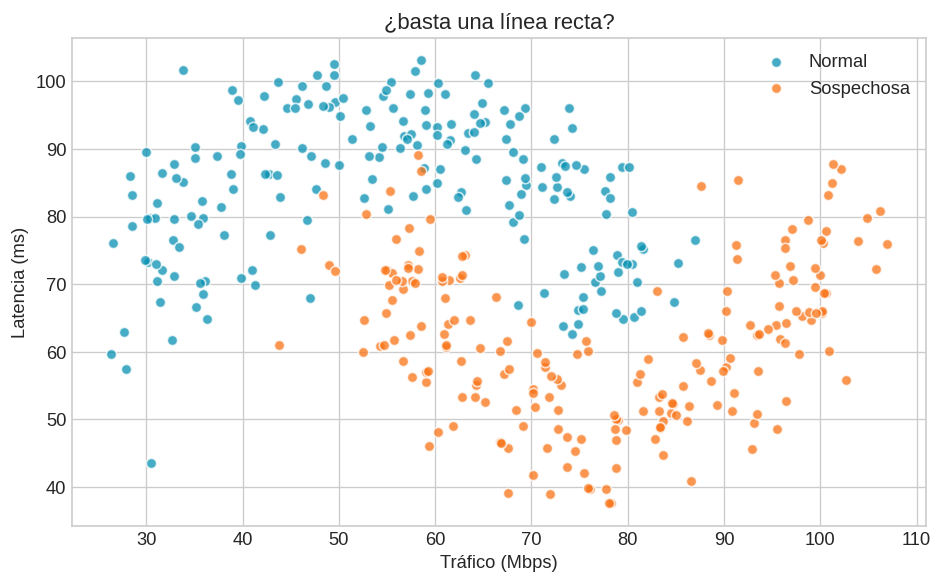

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for clase, nombre in [(0, 'Normal'), (1, 'Sospechosa')]:
    d = datos[datos.clase == clase]
    ax.scatter(d.trafico_mbps, d.latencia_ms, c=COLORES[clase], label=nombre, alpha=.75, edgecolors='white', s=38)
ax.set(xlabel='Tráfico (Mbps)', ylabel='Latencia (ms)', title='¿basta una línea recta?')
ax.legend(); plt.tight_layout(); plt.show()


In [14]:
variables=["trafico_mbps","latencia_ms"]
X=datos[variables]
y=datos["clase"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEMILLA, stratify=y)
print(f"Entrenamiento:{len(X_train)}")
print(f"Prueba:{len(X_test)}")

modelos={
"SVM Lineal": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)),
"SVM Polinomial": make_pipeline(StandardScaler(), SVC(kernel="poly", degree=3, C=1)),
"SVM RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1)),
"SVM Sigmoide": make_pipeline(StandardScaler(), SVC(kernel="sigmoid", C=1)),
"Árbol de Decisión": make_pipeline(DecisionTreeClassifier(max_depth=4, min_samples_leaf=8, random_state=SEMILLA))
          }

Entrenamiento:300
Prueba:100


##Comparar sin mirar las pruebas

* Comparamos mediante validación cruzada estratificada de 5 particiones sobre entrenamiento. Seleccionamos por F1 medio para la clase sospechosa. F1 combina precisión y sensibilidad. Estas son configuraciones iniciales, no una búsqueda exhaustiva.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for nombre, modelo in modelos.items():
    resultado = cross_validate(modelo, X_train, y_train, cv=cv, scoring={'accuracy': 'accuracy', 'f1': 'f1'})
    filas.append({'Modelo': nombre, 'Accuracy CV': resultado['test_accuracy'].mean(), 'F1 CV': resultado['test_f1'].mean(), 'Desviación F1': resultado['test_f1'].std()})
tabla_cv = pd.DataFrame(filas).set_index('Modelo').sort_values('F1 CV', ascending=False)
seleccionado = tabla_cv.index[0]
display(tabla_cv.round(3))
print('Modelo seleccionado por validación:', seleccionado)
for modelo in modelos.values():
    modelo.fit(X_train, y_train)

,Accuracy CV,F1 CV,Desviación F1
Modelo,,,
SVM RBF,0.963,0.963,0.017
Árbol de Decisión,0.870,0.873,0.007
SVM Polinomial,0.850,0.848,0.038
SVM Lineal,0.837,0.838,0.021
SVM Sigmoide,0.673,0.678,0.051


Modelo seleccionado por validación: SVM RBF


##Dibujar las fronteras de los 4 kernels

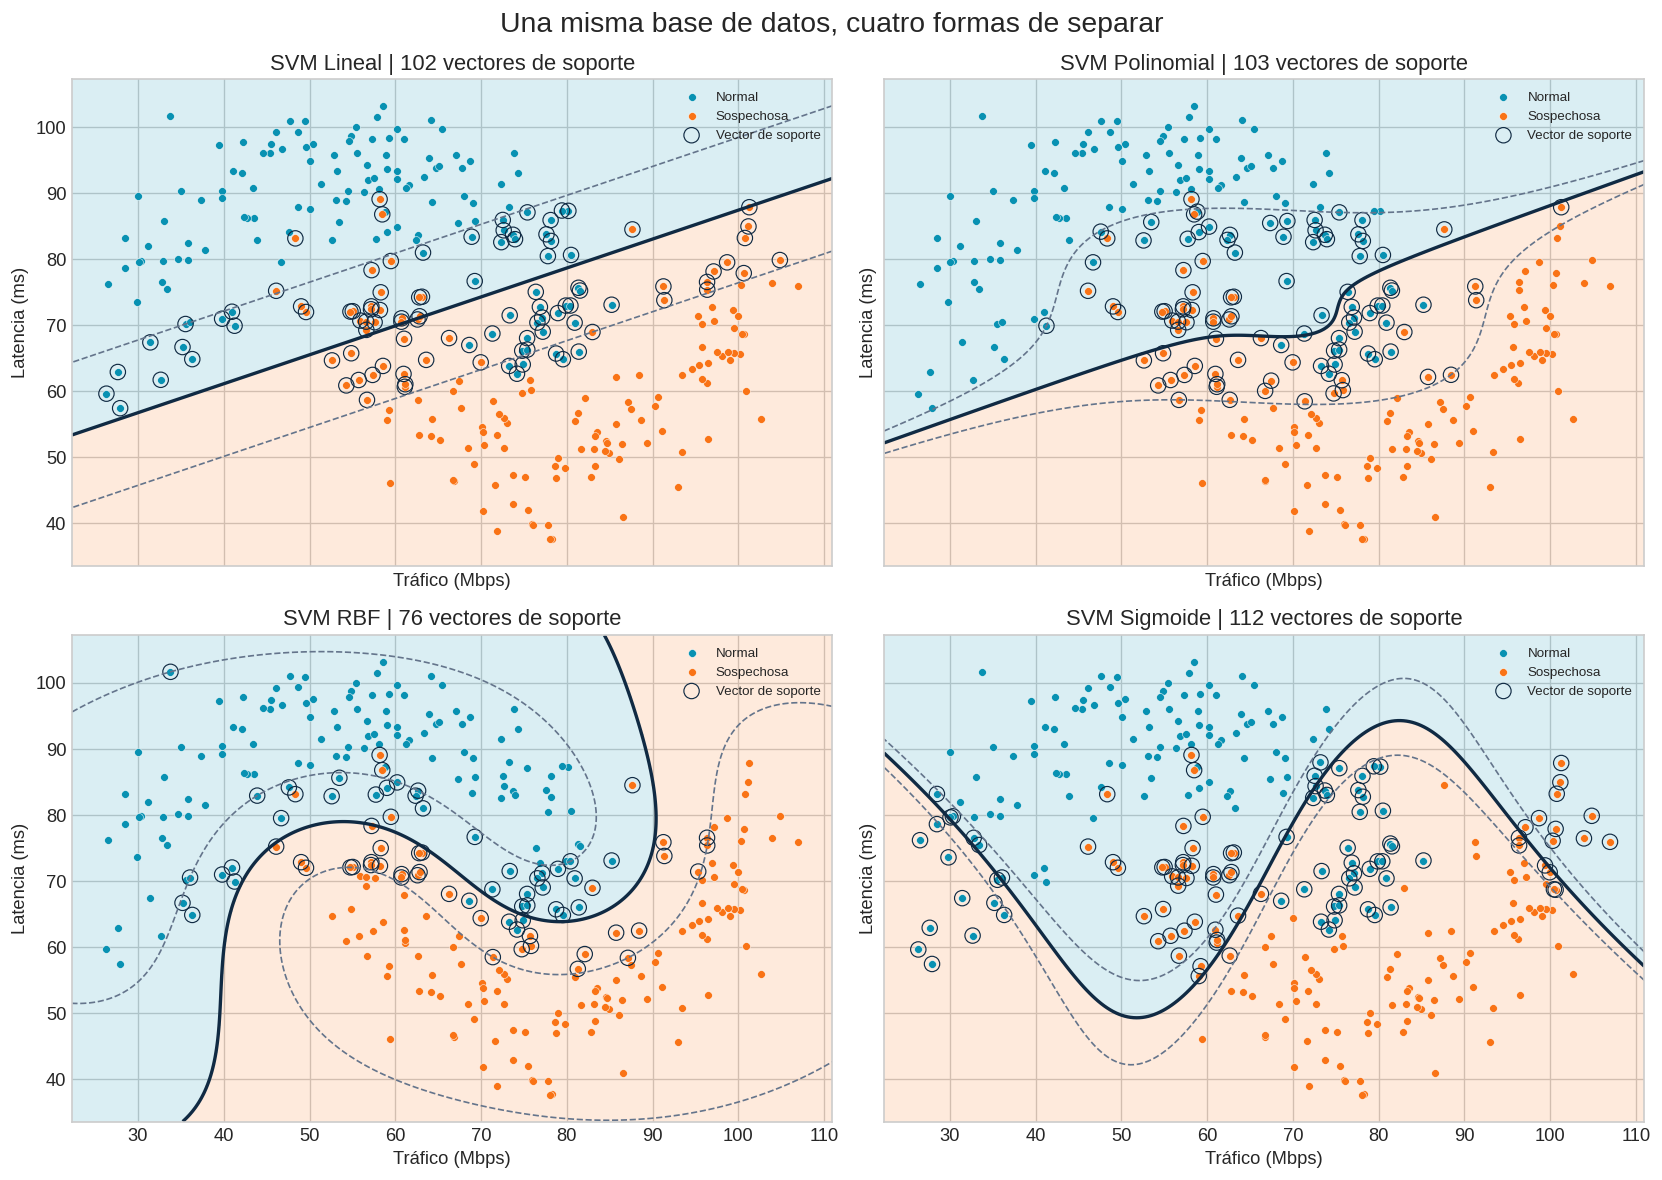

In [16]:
xx, yy = np.meshgrid(np.linspace(X_train.iloc[:,0].min()-4, X_train.iloc[:,0].max()+4, 260),
                     np.linspace(X_train.iloc[:,1].min()-4, X_train.iloc[:,1].max()+4, 260))
rejilla = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=variables)
fig, ejes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, (nombre, modelo) in zip(ejes.ravel(), list(modelos.items())[:4]):
    z = modelo.decision_function(rejilla).reshape(xx.shape)
    ax.contourf(xx, yy, (z > 0).astype(int), levels=[-.5,.5,1.5], colors=COLORES, alpha=.15)
    ax.contour(xx, yy, z, levels=[-1,0,1], colors=['#64748b','#102a43','#64748b'], linestyles=['--','-','--'], linewidths=[1,2,1])
    for clase, etiqueta in [(0,'Normal'),(1,'Sospechosa')]:
        puntos = X_train[y_train == clase]
        ax.scatter(puntos.iloc[:,0], puntos.iloc[:,1], c=COLORES[clase], s=22, label=etiqueta, edgecolors='white', linewidths=.3)
    soporte = X_train.iloc[modelo.named_steps['svc'].support_]
    ax.scatter(soporte.iloc[:,0], soporte.iloc[:,1], s=85, facecolors='none', edgecolors='#102a43', linewidths=.7, label='Vector de soporte')
    ax.set_title(f'{nombre} | {len(soporte)} vectores de soporte')
    ax.set_xlabel('Tráfico (Mbps)'); ax.set_ylabel('Latencia (ms)')
    ax.legend(fontsize=8, loc='best')
fig.suptitle('Una misma base de datos, cuatro formas de separar', fontsize=17)
plt.tight_layout(); plt.show()